# credit card dataset

In [ ]:
# ================================================================
# CREDIT CARD FRAUD DETECTION USING AN AUTOENCODER
# Train on normal transactions only. High reconstruction error = fraud.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = "/content/creditcard.csv"   # change to your path

# ================================================================
# STAGE A: LOAD AND PREPROCESS
# ================================================================
df = pd.read_csv(CSV_PATH)
print("Rows:", len(df))
print(df["Class"].value_counts())

X = df.drop(columns=["Class"]).values.astype("float32")   # 30 PCA features
y = df["Class"].values

# Split first, keeping the fraud ratio the same in both parts
X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Train the autoencoder on NORMAL transactions only
X_normal = X_train_all[y_train_all == 0]
X_train, X_val = train_test_split(X_normal, test_size=0.2, random_state=SEED)

# Scale using normal training data only
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Normal train:", X_train.shape, " Normal val:", X_val.shape, " Test:", X_test.shape)

# ================================================================
# STAGE B: DEFINE THE AUTOENCODER
# ================================================================
autoencoder = models.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(16, activation="relu"),         # encoder
    layers.Dense(8, activation="relu"),          # bottleneck
    layers.Dense(16, activation="relu"),         # decoder
    layers.Dense(30, activation="linear"),       # rebuild 30 features
])
autoencoder.summary()

# ================================================================
# STAGE C: COMPILE AND TRAIN
# ================================================================
autoencoder.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                    loss="mse",
                    metrics=["mae"])

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                     restore_best_weights=True)

history = autoencoder.fit(X_train, X_train,
                          validation_data=(X_val, X_val),
                          epochs=50,
                          batch_size=256,
                          callbacks=[early_stop],
                          verbose=1)

# ================================================================
# STAGE D: RECONSTRUCTION ERROR, THRESHOLD, EVALUATION
# ================================================================
def reconstruction_error(data):
    recon = autoencoder.predict(data, verbose=0)
    return np.mean(np.square(data - recon), axis=1)   # one error per transaction

err_val = reconstruction_error(X_val)
err_test = reconstruction_error(X_test)

# Threshold: 95th percentile of normal validation errors
threshold = np.percentile(err_val, 95)
print(f"\nThreshold: {threshold:.4f}")

y_pred = (err_test > threshold).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=["Normal", "Fraud"], digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, err_test), 4))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = true, columns = predicted):")
print(cm)
print(f"Fraud caught: {cm[1, 1]} of {cm[1].sum()}   "
      f"False alarms: {cm[0, 1]} of {cm[0].sum()} normal")

# ================================================================
# STAGE E: VISUALIZE
# ================================================================
# 1. Training loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Autoencoder training loss (normal transactions only)")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig("fraud_ae_training.png", dpi=150)
plt.show()

# 2. Error distribution: normal vs fraud, with threshold
bins = np.linspace(0, np.percentile(err_test, 99.5), 80)
plt.figure(figsize=(8, 4))
plt.hist(err_test[y_test == 0], bins=bins, alpha=0.6, density=True, label="Normal")
plt.hist(err_test[y_test == 1], bins=bins, alpha=0.6, density=True, label="Fraud")
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.yscale("log")
plt.title("Reconstruction error: normal vs fraud")
plt.xlabel("Reconstruction error (MSE)"); plt.ylabel("Density (log scale)")
plt.legend(); plt.tight_layout()
plt.savefig("fraud_ae_error_hist.png", dpi=150)
plt.show()

# 3. Confusion matrix
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("fraud_ae_confusion.png", dpi=150)
plt.show()

# lstm nasa data

In [ ]:
# ================================================================
# LSTM AUTOENCODER FAULT DETECTION ON NASA TURBOFAN SENSOR DATA
# Train on healthy readings only. High reconstruction error = fault.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = "/content/turbofan.csv"     # change to your path
WINDOW = 30                            # 30 consecutive cycles per input sequence
EPOCHS = 30
BATCH_SIZE = 64

# ================================================================
# STAGE A: LOAD, SPLIT BY ENGINE, SCALE, CREATE WINDOWS
# ================================================================
df = pd.read_csv(CSV_PATH, sep=None, engine="python")
df = df.sort_values(["unit", "cycle"]).reset_index(drop=True)

feature_cols = [c for c in df.columns if c.startswith("setting") or c.startswith("sensor")]
N_FEATURES = len(feature_cols)
print("Engines:", df["unit"].nunique(), " Rows:", len(df), " Features:", N_FEATURES)
print("Fault label counts:\n", df["Fault_Label"].value_counts())

# Split by ENGINE, not by row, so one engine never appears in both train and test
rng = np.random.default_rng(SEED)
units = df["unit"].unique()
rng.shuffle(units)
n_train_units = int(0.7 * len(units))
train_units = units[:n_train_units]
test_units = units[n_train_units:]

train_df = df[df["unit"].isin(train_units)]
test_df = df[df["unit"].isin(test_units)]

# Scale using healthy training readings only
healthy_train = train_df[train_df["Fault_Label"] == 0]
scaler = MinMaxScaler().fit(healthy_train[feature_cols])

def make_windows(data_df):
    # Windows never cross from one engine into another
    X, y, units_out = [], [], []
    for unit_id, g in data_df.groupby("unit"):
        feats = scaler.transform(g[feature_cols])
        labels = g["Fault_Label"].values
        for i in range(len(g) - WINDOW + 1):
            X.append(feats[i:i + WINDOW])
            y.append(labels[i:i + WINDOW].max())   # window is faulty if any reading is faulty
            units_out.append(unit_id)
    return np.array(X), np.array(y), np.array(units_out)

X_tr, y_tr, _ = make_windows(train_df)
X_te, y_te, u_te = make_windows(test_df)

# Training uses healthy windows only
X_healthy = X_tr[y_tr == 0]
X_fit, X_val = train_test_split(X_healthy, test_size=0.1, random_state=SEED)

print("Healthy train windows:", X_fit.shape, " Healthy val windows:", X_val.shape)
print("Test windows:", X_te.shape, " Faulty test windows:", y_te.sum())

# ================================================================
# STAGE B: DEFINE THE LSTM AUTOENCODER
# ================================================================
model = models.Sequential([
    layers.Input(shape=(WINDOW, N_FEATURES)),
    layers.LSTM(64),                                     # encoder: sequence -> summary vector
    layers.RepeatVector(WINDOW),                         # repeat summary for each time step
    layers.LSTM(64, return_sequences=True),              # decoder: rebuild the sequence
    layers.TimeDistributed(layers.Dense(N_FEATURES)),    # rebuild all sensors at each step
])
model.summary()

# ================================================================
# STAGE C: TRAIN ON HEALTHY READINGS ONLY
# ================================================================
model.compile(optimizer="adam", loss="mse")

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                     restore_best_weights=True)

history = model.fit(X_fit, X_fit,
                    validation_data=(X_val, X_val),
                    epochs=EPOCHS,
                    batch_size=BATCH_SIZE,
                    callbacks=[early_stop],
                    verbose=1)

# ================================================================
# STAGE D: RECONSTRUCTION ERROR, THRESHOLD, DETECTION
# ================================================================
def reconstruction_error(data):
    recon = model.predict(data, verbose=0)
    return np.mean(np.square(data - recon), axis=(1, 2))   # one error per window

err_val = reconstruction_error(X_val)
err_te = reconstruction_error(X_te)

# Threshold from healthy validation windows only
threshold = np.percentile(err_val, 99)
print(f"\nThreshold (99th percentile of healthy errors): {threshold:.6f}")

y_pred = (err_te > threshold).astype(int)

# ================================================================
# STAGE E: EVALUATION
# ================================================================
print("\nClassification Report:")
print(classification_report(y_te, y_pred,
                            target_names=["Healthy", "Fault"], digits=4))
print("ROC-AUC:", round(roc_auc_score(y_te, err_te), 4))

cm = confusion_matrix(y_te, y_pred)
print("Confusion matrix (rows = true, columns = predicted):")
print(cm)
print(f"Faults caught: {cm[1, 1]} of {cm[1].sum()}   "
      f"False alarms: {cm[0, 1]} of {cm[0].sum()} healthy windows")

# ================================================================
# STAGE F: VISUALIZE
# ================================================================
# 1. Error distribution: healthy vs faulty windows
bins = np.linspace(0, np.percentile(err_te, 99.5), 60)
plt.figure(figsize=(8, 4))
plt.hist(err_te[y_te == 0], bins=bins, alpha=0.6, density=True, label="Healthy")
plt.hist(err_te[y_te == 1], bins=bins, alpha=0.6, density=True, label="Fault")
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.title("Reconstruction error: healthy vs faulty windows")
plt.xlabel("Reconstruction error (MSE)"); plt.ylabel("Density")
plt.legend(); plt.tight_layout()
plt.savefig("turbofan_error_hist.png", dpi=150)
plt.show()

# 2. Error over time for one test engine, with fault periods shaded
unit_id = test_units[0]
mask = u_te == unit_id
plt.figure(figsize=(12, 4))
plt.plot(err_te[mask], label="Reconstruction error")
plt.axhline(threshold, color="red", linestyle="--", label="Threshold")
plt.fill_between(np.arange(mask.sum()), 0, err_te[mask].max(),
                 where=y_te[mask] == 1, color="orange", alpha=0.3, label="True fault")
plt.title(f"Engine {unit_id}: reconstruction error over cycles")
plt.xlabel("Window index (cycle order)"); plt.ylabel("MSE")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("turbofan_engine_error.png", dpi=150)
plt.show()

# 3. Training curve
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("LSTM autoencoder training loss (healthy readings only)")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig("turbofan_training.png", dpi=150)
plt.show()

# sign language mnist

In [ ]:
# ================================================================
# AUTOENCODER ANOMALY DETECTION ON SIGN LANGUAGE MNIST
# Anomaly = letter Y (label 24). Autoencoder trained on the other 23 letters.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TRAIN_PATH = "/content/train.csv"     # change to your path
TEST_PATH = "/content/test.csv"       # change to your path
ANOMALY_LABEL = 24                    # label 24 = letter Y
ANOMALY_NAME = "Y"

# ================================================================
# STAGE A: LOAD AND PREPROCESS
# ================================================================
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

def to_pixels(df):
    # Each row is 784 pixel values; scale to 0-1
    return df.drop(columns=["label"]).values.astype("float32") / 255.0

# Training data: only the 23 normal letters (everything except Y)
normal_df = train_df[train_df["label"] != ANOMALY_LABEL]
X_normal = to_pixels(normal_df)

# Hold out 10% of the normal data for validation and threshold setting
X_train, X_val = train_test_split(X_normal, test_size=0.1, random_state=SEED)

# Test data: all letters, including Y
X_test = to_pixels(test_df)
y_test = test_df["label"].values
is_anomaly = (y_test == ANOMALY_LABEL).astype(int)   # 1 = Y, 0 = other letters

print("Normal training images:", X_train.shape)
print("Normal validation images:", X_val.shape)
print("Test images:", X_test.shape, " Y in test:", is_anomaly.sum())

# ================================================================
# STAGE B: DEFINE THE AUTOENCODER (encoder -> bottleneck -> decoder)
# ================================================================
autoencoder = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),        # encoder
    layers.Dense(32, activation="relu"),         # bottleneck (compressed code)
    layers.Dense(128, activation="relu"),        # decoder
    layers.Dense(784, activation="sigmoid"),     # rebuild 784 pixels (0-1)
])
autoencoder.summary()

# ================================================================
# STAGE C: TRAIN ON NORMAL LETTERS ONLY
# ================================================================
autoencoder.compile(optimizer="adam", loss="mse")

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                     restore_best_weights=True)

# Input and target are the same: the model learns to rebuild normal letters
history = autoencoder.fit(X_train, X_train,
                          validation_data=(X_val, X_val),
                          epochs=50,
                          batch_size=128,
                          callbacks=[early_stop],
                          verbose=1)

# ================================================================
# STAGE D: RECONSTRUCTION ERROR, THRESHOLD, DETECTION
# ================================================================
def reconstruction_error(data):
    recon = autoencoder.predict(data, verbose=0)
    return np.mean(np.square(data - recon), axis=1)   # one error per image

err_val = reconstruction_error(X_val)
err_test = reconstruction_error(X_test)

# Threshold: 95th percentile of normal validation errors
# (Y images are never used to set the threshold)
threshold = np.percentile(err_val, 95)
print(f"\nThreshold (95th percentile of normal errors): {threshold:.5f}")

y_pred = (err_test > threshold).astype(int)

# ================================================================
# STAGE E: EVALUATION
# ================================================================
print("\nClassification Report:")
print(classification_report(is_anomaly, y_pred,
                            target_names=["Normal (other 23)", f"Anomaly ({ANOMALY_NAME})"],
                            digits=4))
print("ROC-AUC:", round(roc_auc_score(is_anomaly, err_test), 4))

cm = confusion_matrix(is_anomaly, y_pred)
print("Confusion matrix (rows = true, columns = predicted):")
print(cm)
print(f"Detected {ANOMALY_NAME}: {cm[1, 1]} of {cm[1].sum()}   "
      f"False alarms: {cm[0, 1]} of {cm[0].sum()} other letters")

# ================================================================
# STAGE F: VISUALIZE
# ================================================================
# 1. Error distribution: normal letters vs Y, with threshold
bins = np.linspace(0, np.percentile(err_test, 99.5), 60)
plt.figure(figsize=(8, 4))
plt.hist(err_test[is_anomaly == 0], bins=bins, alpha=0.6, density=True,
         label="Other letters (normal)")
plt.hist(err_test[is_anomaly == 1], bins=bins, alpha=0.6, density=True,
         label=f"Letter {ANOMALY_NAME} (anomaly)")
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.title("Reconstruction error: normal letters vs Y")
plt.xlabel("Reconstruction error (MSE)"); plt.ylabel("Density")
plt.legend(); plt.tight_layout()
plt.savefig("sign_mnist_ae_error.png", dpi=150)
plt.show()

# 2. Original vs reconstructed images, normal and anomalous
normal_idx = np.where(is_anomaly == 0)[0][:5]
anom_idx = np.where(is_anomaly == 1)[0][:5]
rows = [("Normal: original", X_test[normal_idx]),
        ("Normal: rebuilt", autoencoder.predict(X_test[normal_idx], verbose=0)),
        (f"{ANOMALY_NAME}: original", X_test[anom_idx]),
        (f"{ANOMALY_NAME}: rebuilt", autoencoder.predict(X_test[anom_idx], verbose=0))]

fig, axes = plt.subplots(4, 5, figsize=(10, 9))
for r, (title, imgs) in enumerate(rows):
    for c in range(5):
        axes[r, c].imshow(imgs[c].reshape(28, 28), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("sign_mnist_ae_reconstructions.png", dpi=150)
plt.show()

# 3. Training curve
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Autoencoder training loss (normal letters only)")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig("sign_mnist_ae_training.png", dpi=150)
plt.show()

#LSTM Energy

In [ ]:
# ================================================================
# LSTM AUTOENCODER ANOMALY DETECTION ON SMART GRID ENERGY DATA
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = "/content/smart_grid.csv"    # change to your path
WINDOW = 24                              # 24 time steps per input sequence
EPOCHS = 30
BATCH_SIZE = 64

# ================================================================
# STAGE A: LOADING AND PREPROCESSING THE DATA
# ================================================================
df = pd.read_csv(CSV_PATH)
print("Columns:", df.columns.tolist())
print("Rows:", len(df))

# Keep only the consumption column and the timestamp (adjust names to your file)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").set_index("timestamp")
series = df["consumption"]

# Fill missing values: interpolate in time, then fill any gaps at the edges
series = series.interpolate(method="time").bfill().ffill()

# Normalize to 0-1. Fit the scaler on the first 80% only (the training part)
split = int(0.8 * len(series))
scaler = MinMaxScaler().fit(series.values[:split].reshape(-1, 1))
scaled = scaler.transform(series.values.reshape(-1, 1)).flatten()

# Create sliding time windows: each sample is WINDOW consecutive readings
def make_windows(data, window):
    return np.array([data[i:i + window] for i in range(len(data) - window + 1)])

X = make_windows(scaled, WINDOW)[..., np.newaxis]     # shape (n, WINDOW, 1)
X_train = X[:split - WINDOW + 1]                       # windows fully inside the training part
X_test = X[split - WINDOW + 1:]

print("Train windows:", X_train.shape, " Test windows:", X_test.shape)

# ================================================================
# STAGE B: DEFINE THE LSTM AUTOENCODER
# ================================================================
model = models.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(64),                                   # encoder: sequence -> one vector
    layers.RepeatVector(WINDOW),                       # repeat the summary for each time step
    layers.LSTM(64, return_sequences=True),            # decoder: rebuild the sequence
    layers.TimeDistributed(layers.Dense(1)),           # one value per time step
])
model.summary()

# ================================================================
# STAGE C: TRAIN ON NORMAL DATA ONLY
# ================================================================
model.compile(optimizer="adam", loss="mse")

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                     restore_best_weights=True)

# Input and target are the same: the model learns to reproduce normal patterns
history = model.fit(X_train, X_train,
                    validation_split=0.1,
                    epochs=EPOCHS,
                    batch_size=BATCH_SIZE,
                    callbacks=[early_stop],
                    verbose=1)

# ================================================================
# STAGE D: THRESHOLD AND ANOMALY DETECTION
# ================================================================
def reconstruction_error(data):
    recon = model.predict(data, verbose=0)
    return np.mean(np.square(data - recon), axis=(1, 2))   # one error per window

train_err = reconstruction_error(X_train)
test_err = reconstruction_error(X_test)

# Threshold: 99th percentile of normal (training) errors
threshold = np.percentile(train_err, 99)
print(f"\nThreshold: {threshold:.6f}")

anomalies = test_err > threshold
print(f"Anomalous windows in test set: {anomalies.sum()} of {len(anomalies)}")

# ================================================================
# STAGE E: VISUALIZE RESULTS
# ================================================================
# Error over time with the threshold
plt.figure(figsize=(12, 4))
plt.plot(test_err, label="Reconstruction error")
plt.axhline(threshold, color="red", linestyle="--", label="Threshold")
plt.title("Reconstruction error on test windows")
plt.xlabel("Window index"); plt.ylabel("MSE")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("smart_grid_error.png", dpi=150)
plt.show()

# Consumption curve with flagged anomalies
test_index = series.index[split:]                      # timestamp of each test reading
flag_idx = np.where(anomalies)[0]
flag_time = test_index[flag_idx + WINDOW - 1]          # end point of each flagged window
plt.figure(figsize=(12, 4))
plt.plot(series.index[split:], series.values[split:], label="Consumption")
plt.scatter(flag_time, series.loc[flag_time].values, color="red", s=12, label="Anomaly")
plt.title("Consumption with detected anomalies")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("smart_grid_anomalies.png", dpi=150)
plt.show()

# Training curve
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("LSTM Autoencoder Training Loss")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig("smart_grid_training.png", dpi=150)
plt.show()

# Practise

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/SEM7/creditcard.csv")


In [ ]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=["Class"]).values.astype("float32")
y = df["Class"].values.astype("int64")

In [ ]:
import tensorflow as tf
import numpy as np
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
from sklearn.model_selection import train_test_split

X_train_all, X_test, y_train_all, y_test = train_test_split(X, y, random_state = SEED, stratify=y, test_size=0.2)

In [ ]:
X_normal = X_train_all[y_train_all==0]

In [ ]:
X_train, X_val = train_test_split(X_normal, test_size=0.2, random_state=SEED)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
input_dim = X_train.shape[1]

In [ ]:
from tensorflow.keras import layers, Sequential

autoencoder = Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])

autoencoder.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 30)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras import optimizers
autoencoder.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [ ]:
from tensorflow.keras import callbacks

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

In [ ]:
history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.8120 - mae: 0.6092 - val_loss: 0.6659 - val_mae: 0.5560
Epoch 2/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6278 - mae: 0.5397 - val_loss: 0.5890 - val_mae: 0.5225
Epoch 3/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5679 - mae: 0.5106 - val_loss: 0.5461 - val_mae: 0.4981
Epoch 4/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5369 - mae: 0.4937 - val_loss: 0.5237 - val_mae: 0.4855
Epoch 5/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5161 - mae: 0.4832 - val_loss: 0.5072 - val_mae: 0.4769
Epoch 6/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5005 - mae: 0.4753 - val_loss: 0.4938 - val_mae: 0.4696
Epoch 7/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4876 - mae: 0.4671 - val_loss: 0.4823 - val_mae: 0.4613
Epoch 8/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4784 - mae: 0.4600 - val_loss: 0.4746 - val_mae: 0.4555
Epoch 9/200
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/

In [ ]:
def reconstruction_error(model, data):
  reconstruction = model.predict(data,verbose=0)
  return np.mean(np.square(data-reconstruction),axis=1)

In [ ]:
err_val = reconstruction_error(autoencoder, X_val)
err_test = reconstruction_error(autoencoder,X_test)

In [ ]:
print(f"validation error: {err_val} test error: {err_test}")

validation error: [0.10630377 0.61574095 0.16795263 ... 0.31403875 0.36042514 0.5394878 ] test error: [0.21413033 1.4030826  1.6815857  ... 0.5289916  0.09045486 0.29392806]


In [ ]:
threshold = np.percentile(err_val,95)

In [ ]:
print(threshold)

0.9557276


In [ ]:
y_pred = (err_test > threshold).astype(int)

In [ ]:
print(y_pred)

[0 1 1 ... 0 0 0]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Normal", "Fraud"], digits=4))

              precision    recall  f1-score   support

      Normal     0.9997    0.9485    0.9734     56864
       Fraud     0.0279    0.8571    0.0540        98

    accuracy                         0.9483     56962
   macro avg     0.5138    0.9028    0.5137     56962
weighted avg     0.9981    0.9483    0.9718     56962



In [ ]:
from sklearn.metrics import roc_auc_score
print("ROC AUC SCORE: ",round(roc_auc_score(y_test,err_test),4))

ROC AUC SCORE:  0.9421


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(f"Caught fraud {cm[1,1]} of {cm[1].sum()}")
print(f"False alarms {cm[0,1]} of {cm[0].sum()} normal")

Caught fraud 84 of 98
False alarms 2931 of 56864 normal


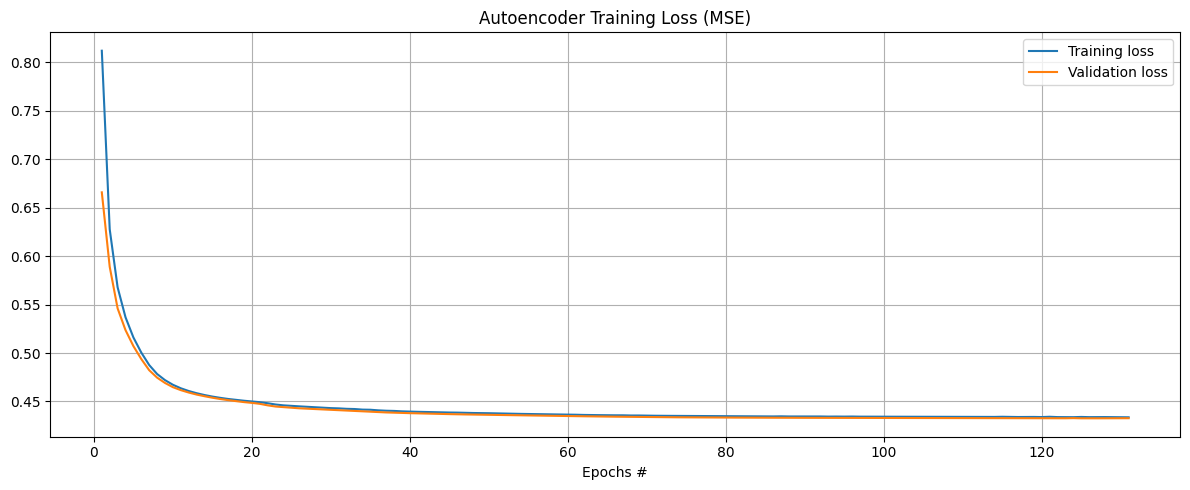

In [ ]:
import matplotlib.pyplot as plt
epochs_range = range(1, len(history.history["loss"])+1)
plt.figure(figsize=(12,5))
plt.plot(epochs_range,history.history["loss"],label="Training loss")
plt.plot(epochs_range,history.history["val_loss"],label="Validation loss")
plt.legend()
plt.title("Autoencoder Training Loss (MSE)")
plt.xlabel("Epochs #")
plt.grid()
plt.tight_layout()
plt.show()

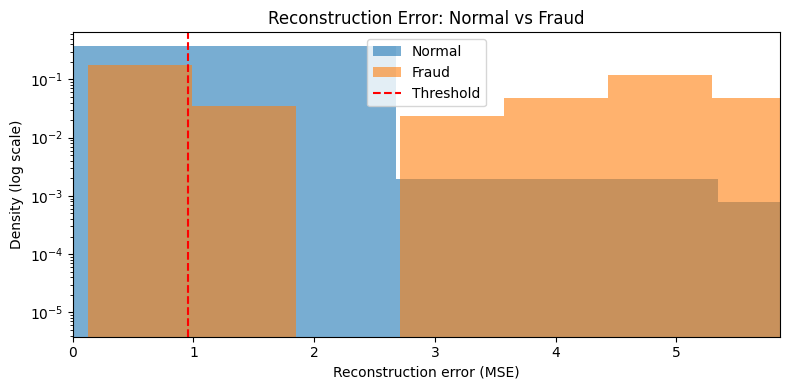

In [ ]:
plt.figure(figsize=(8,4))
bins = np.linspace(0, np.percentile(err_test, 99.5), 80)
plt.hist(err_test[y_test == 0], bins=bins, alpha=0.6, density=True, label="Normal")
plt.hist(err_test[y_test == 1], bins=bins, alpha=0.6, density=True, label="Fraud")
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.yscale("log")
plt.xlim(0, np.percentile(err_test, 99.5))
plt.title("Reconstruction Error: Normal vs Fraud")
plt.xlabel("Reconstruction error (MSE)"); plt.ylabel("Density (log scale)")
plt.legend(); plt.tight_layout()
plt.show()

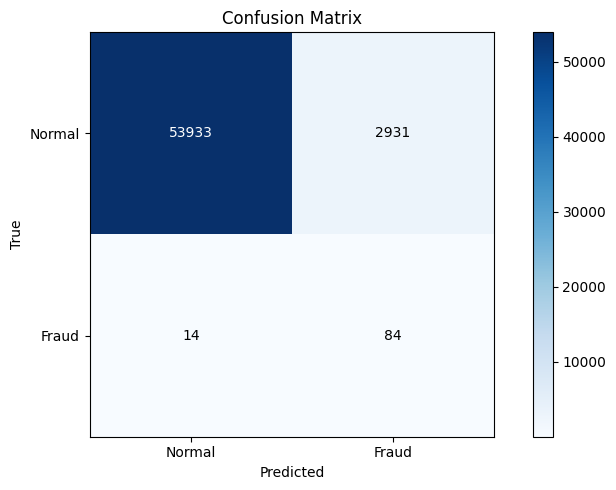

In [ ]:
plt.figure(figsize=(8,5))
plt.imshow(cm, cmap="Blues")
plt.xticks([0,1],["Normal", "Fraud"])
plt.yticks([0,1],["Normal","Fraud"])
plt.colorbar()
for i in range(2):
  for j in range(2):
    plt.text(j,i,cm[i,j],ha="center",va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()